# 00 · Run the whole pipeline in one Colab session

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Souhaila-DJAFFAL/longtail-recsys/blob/main/notebooks/00_run_all.ipynb)

Each Colab notebook normally gets its own machine, so files saved by one notebook (the processed
dataset, the trained models) are not visible to the next. This notebook runs **01 → 05 in a single
session**, saves every notebook **with its outputs and figures**, and packages them for upload to GitHub.



In [1]:
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (switch to a T4 GPU runtime)")

!rm -rf /content/longtail-recsys
!git clone -q https://github.com/Souhaila-DJAFFAL/longtail-recsys.git /content/longtail-recsys
%cd /content/longtail-recsys
!pip install -q tabulate nbconvert

GPU: Tesla T4
/content/longtail-recsys


In [2]:
import os, subprocess, time

os.environ["RECSYS_DATASET"] = "ml-1m"
os.environ["RECSYS_QUICK"] = "0"
NOTEBOOKS = ["01_data_preparation_and_eda.ipynb", "02_models.ipynb", "03_evaluation_metrics.ipynb",
             "04_training.ipynb", "05_results_and_longtail_analysis.ipynb"]

for nb in NOTEBOOKS:
    t0 = time.time()
    print(f"Running {nb} ...", flush=True)
    r = subprocess.run(["jupyter", "nbconvert", "--to", "notebook", "--execute", "--inplace",
                        "--ExecutePreprocessor.timeout=-1", f"notebooks/{nb}"],
                       capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stderr[-3000:])
        raise RuntimeError(f"{nb} failed; see the error above")
    print(f"  done in {(time.time() - t0) / 60:.1f} min")

Running 01_data_preparation_and_eda.ipynb ...
  done in 0.3 min
Running 02_models.ipynb ...
  done in 0.2 min
Running 03_evaluation_metrics.ipynb ...
  done in 0.2 min
Running 04_training.ipynb ...
  done in 9.9 min
Running 05_results_and_longtail_analysis.ipynb ...
  done in 0.3 min


## Results

### Test results (ml-1m, full ranking, K=10)

| model      |   HR@10 |   NDCG@10 |   NDCG@10 head |   NDCG@10 tail |   Coverage@10 |   TailShare@10 |    ARP@10 |
|:-----------|--------:|----------:|---------------:|---------------:|--------------:|---------------:|----------:|
| Popularity |  0.0369 |    0.0180 |         0.0309 |         0.0000 |        0.0583 |         0.0000 | 2513.7842 |
| BPR-MF     |  0.0801 |    0.0399 |         0.0616 |         0.0095 |        0.5597 |         0.1123 | 1352.8610 |
| SASRec     |  0.2459 |    0.1315 |         0.1739 |         0.0721 |        0.6964 |         0.2776 |  925.9801 |

### Popularity-aware re-ranking

| model   |   lambda |   NDCG@10 |   NDCG@10 tail |   Coverage@10 |   TailShare@10 |    ARP@10 |
|:--------|---------:|----------:|---------------:|--------------:|---------------:|----------:|
| BPR-MF  |   0.0000 |    0.0399 |         0.0095 |        0.5597 |         0.1123 | 1352.8610 |
| BPR-MF  |   0.1000 |    0.0403 |         0.0108 |        0.5978 |         0.1385 | 1288.0083 |
| BPR-MF  |   0.2500 |    0.0393 |         0.0127 |        0.6622 |         0.1868 | 1184.1492 |
| BPR-MF  |   0.5000 |    0.0370 |         0.0173 |        0.7939 |         0.2973 |  990.5878 |
| BPR-MF  |   0.7500 |    0.0332 |         0.0217 |        0.9330 |         0.4519 |  767.3625 |
| BPR-MF  |   1.0000 |    0.0237 |         0.0226 |        0.9939 |         0.6873 |  450.2457 |
| SASRec  |   0.0000 |    0.1315 |         0.0721 |        0.6964 |         0.2776 |  925.9801 |
| SASRec  |   0.1000 |    0.1259 |         0.0819 |        0.7725 |         0.3552 |  808.7426 |
| SASRec  |   0.2500 |    0.1112 |         0.0904 |        0.8809 |         0.5114 |  611.6553 |
| SASRec  |   0.5000 |    0.0604 |         0.0756 |        0.9356 |         0.8318 |  249.0587 |
| SASRec  |   0.7500 |    0.0216 |         0.0438 |        0.7108 |         0.9877 |   58.1973 |
| SASRec  |   1.0000 |    0.0094 |         0.0223 |        0.4479 |         0.9998 |   25.0156 |

### Key findings

- SASRec reaches NDCG@10 = 0.1315, +229.7% vs. BPR-MF and +629.1% vs. Popularity.
- For users whose target is a tail item, NDCG@10 is 0.0721 (SASRec) and 0.0095 (BPR-MF), against 0.1739 and 0.0616 for head targets.
- Tail items make up 27.8% (SASRec) and 11.2% (BPR-MF) of top-10 lists; catalogue coverage is 69.6% and 56.0%.
- BPR-MF re-ranked with λ = 0.25 keeps ≥95% of its NDCG@10 (0.0393 vs. 0.0399) while tail share goes from 11.2% to 18.7% and coverage from 56.0% to 66.2%.
- SASRec re-ranked with λ = 0.1 keeps ≥95% of its NDCG@10 (0.1259 vs. 0.1315) while tail share goes from 27.8% to 35.5% and coverage from 69.6% to 77.3%.


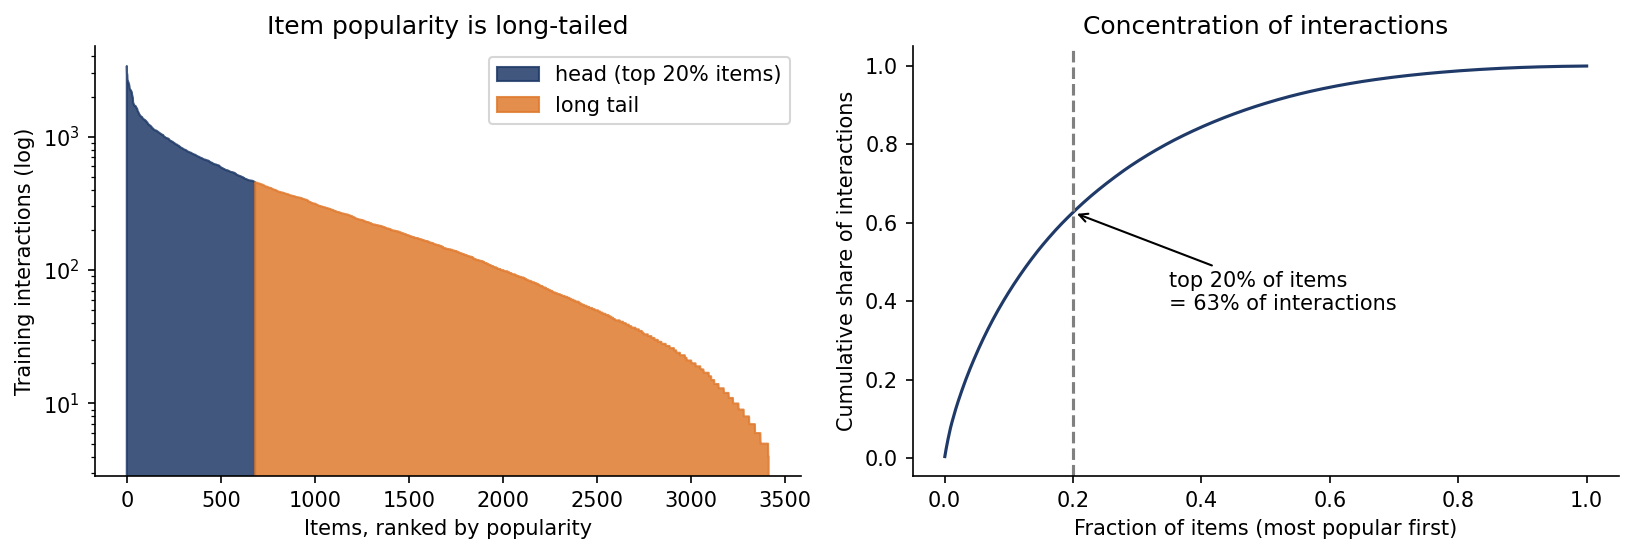

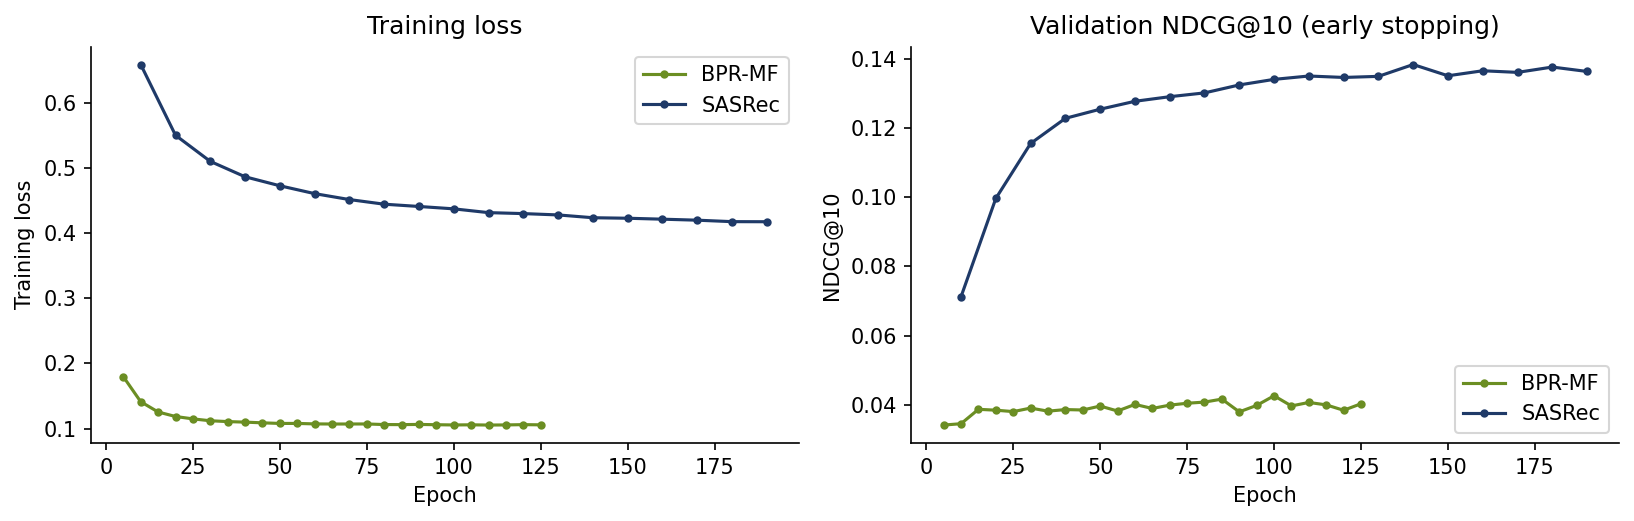

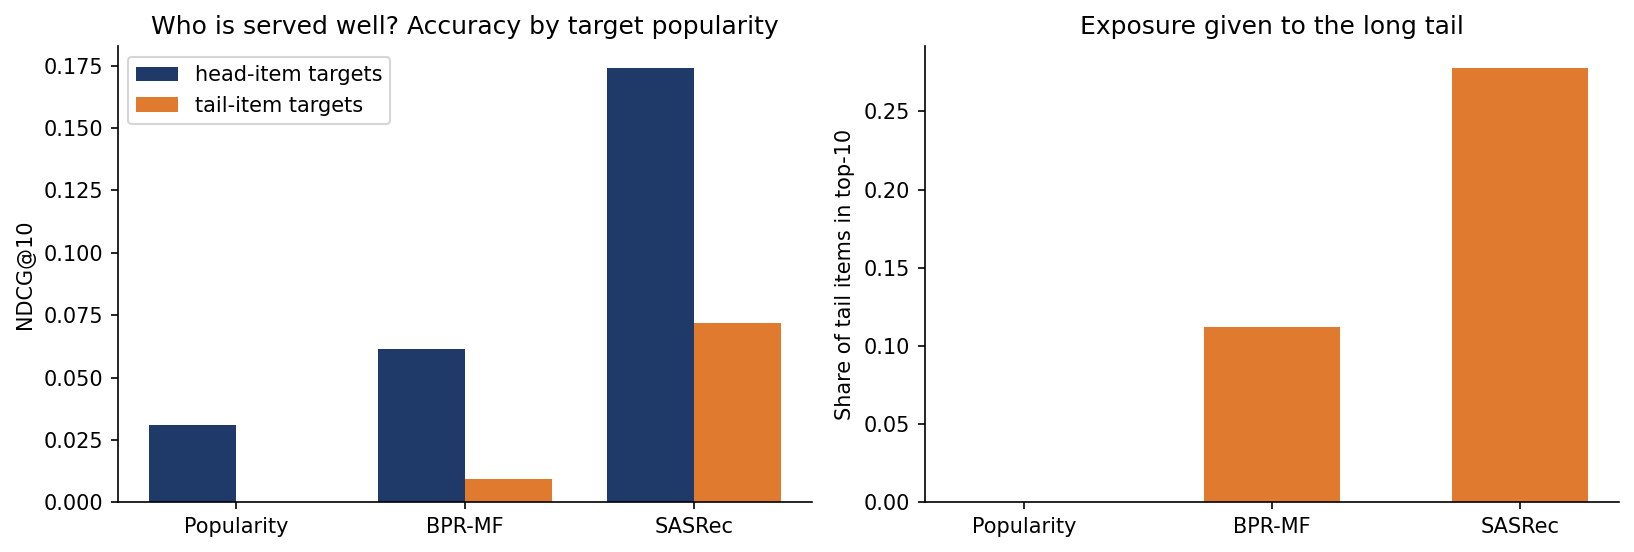

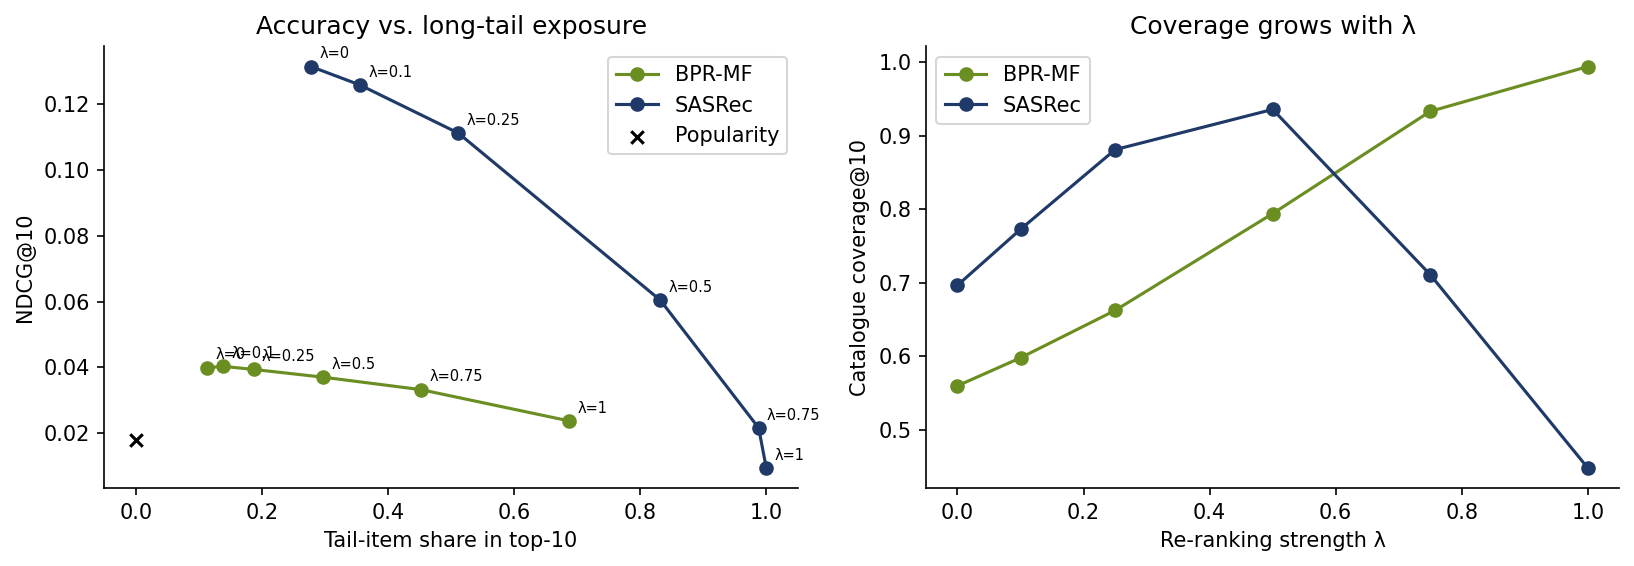

In [3]:
from IPython.display import Markdown, Image, display
display(Markdown(open("results/results_ml-1m.md").read()))
for fig in ["eda_long_tail.png", "learning_curves.png", "head_vs_tail.png", "tradeoff.png"]:
    display(Image(f"results/{fig}", width=850))

## Download and upload to GitHub

The cell below downloads `longtail-recsys-results.zip` containing the five executed notebooks and the
`results/` folder. On GitHub, open the repository, click **Add file → Upload files**, drag in the
`notebooks` and `results` folders from the unzipped archive, and click **Commit changes**
(existing notebooks are replaced by the versions with outputs).

In [4]:
!zip -q -r longtail-recsys-results.zip notebooks results
from google.colab import files
files.download("longtail-recsys-results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>